In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Importing Libraries

In [ ]:
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    confusion_matrix,classification_report,ConfusionMatrixDisplay,recall_score,f1_score,accuracy_score,
    precision_score,roc_auc_score,roc_curve,precision_recall_curve,average_precision_score
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',None)
os.makedirs('images',exist_ok=True)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi']=100


# Loading Dataset

In [3]:
data=pd.read_csv('telecom_churn.csv')

In [4]:
data.shape

(3333, 11)

In [5]:
data.shape[0],data.shape[1]

(3333, 11)

# Data Understanding

In [6]:
data.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

In [7]:
data.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [8]:
# Churn - Target -  1=churned,0=stayed
# AccountWeeks - Numeric -  How long the customer has had an active account
# ContractRenewal - Binary - 1=recently renewed , 0=did not renew
# DataPlan - Binary - 1=has data plan , 0 = no data plan
# DataUsage -  Numeric - Monthly data usage in GB
# CustServCalls - Numeric - Number of customer service calls made
# DayMins - Numeric - Avergae daytime minutes used per month
# DayCalls - Numeric - Average number of daytime calls
# MonthlyCharge - Numeric - Average monthly bill
# OverageFee - Numeric - Largest average fee in last 12 months
# RoamMins - Numeric - Average roaming minutes per month

In [9]:
print('Data Types:')
print(data.dtypes)
print(f'\nMising values : {data.isnull().sum().sum()}')
print(f'Duplicate rows: {data.duplicated().sum()}')

Data Types:
Churn                int64
AccountWeeks         int64
ContractRenewal      int64
DataPlan             int64
DataUsage          float64
CustServCalls        int64
DayMins            float64
DayCalls             int64
MonthlyCharge      float64
OverageFee         float64
RoamMins           float64
dtype: object

Mising values : 0
Duplicate rows: 0


In [10]:
# Statistical summary

data.describe().round(2)

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.00,3333.00,3333.0,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00
mean,0.14,101.06,0.9,0.28,0.82,1.56,179.78,100.44,56.31,10.05,10.24
std,0.35,39.82,0.3,0.45,1.27,1.32,54.47,20.07,16.43,2.54,2.79
min,0.00,1.00,0.0,0.00,0.00,0.00,0.00,0.00,14.00,0.00,0.00
25%,0.00,74.00,1.0,0.00,0.00,1.00,143.70,87.00,45.00,8.33,8.50
50%,0.00,101.00,1.0,0.00,0.00,1.00,179.40,101.00,53.50,10.07,10.30
75%,0.00,127.00,1.0,1.00,1.78,2.00,216.40,114.00,66.20,11.77,12.10
max,1.00,243.00,1.0,1.00,5.40,9.00,350.80,165.00,111.30,18.19,20.00


# Exploratory Data Analysis (EDA)

The objective of EDA is to understand the customer behaviour , identify relationships between variabels,
detect class imbalace, and discover which factor are most associatred with churn

In [11]:
churn_counts  = data['Churn'].value_counts()
churn_counts.values

array([2850,  483])

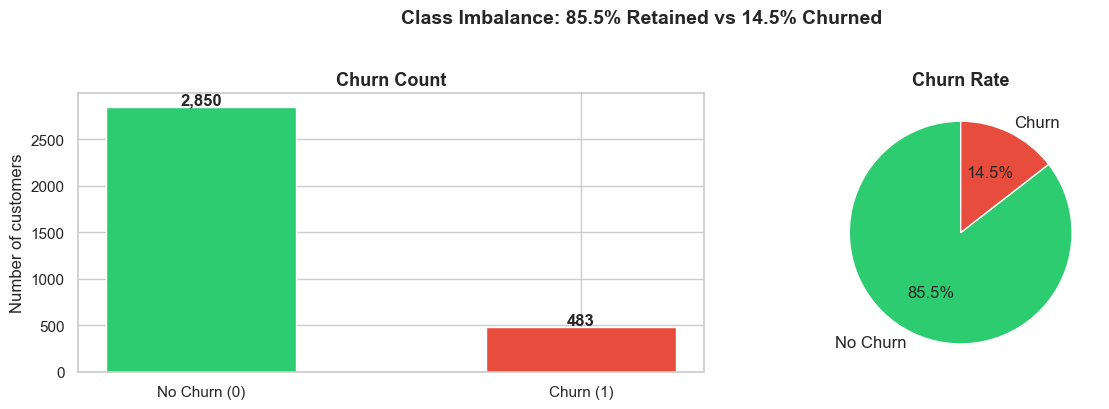

In [12]:
# Traget Distribution

fig, axes = plt.subplots(1,2,figsize=(13,4))
churn_counts  = data['Churn'].value_counts()

bars = axes[0].bar(['No Churn (0)', 'Churn (1)'], churn_counts.values,
                    color=['#2ecc71','#e74c3c'],edgecolor='white',width=0.5)

axes[0].set_title('Churn Count' , fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of customers')


for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2 , bar.get_height() + 25,
                 f'{int(bar.get_height()):,}', ha='center',fontsize=12,fontweight='bold')

axes[1].pie(churn_counts.values,labels=['No Churn','Churn'],
            autopct='%1.1f%%', colors=['#2ecc71','#e74c3c'],
            startangle=90,textprops={'fontsize':12})
axes[1].set_title('Churn Rate',fontsize=13,fontweight='bold')


plt.suptitle('Class Imbalance: 85.5% Retained vs 14.5% Churned',
             fontsize=14,fontweight='bold',y=1.02)

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
data.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

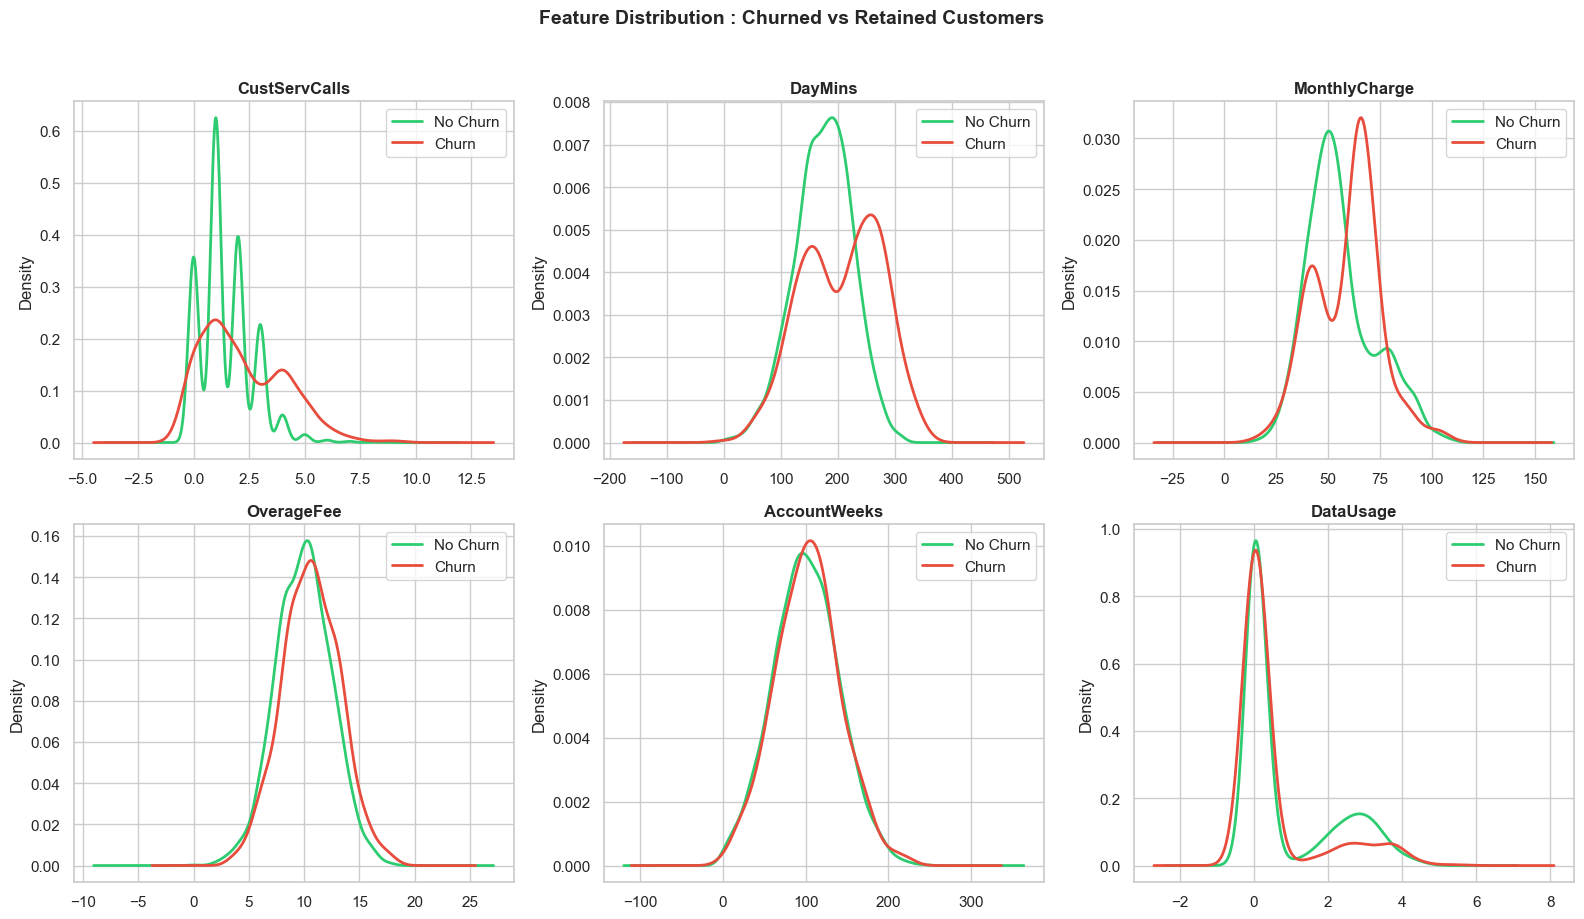

In [14]:
# Feature Distributions
# comparing distributions between churned and retained customers

fig, axes=plt.subplots(2,3,figsize=(16,9))
axes=axes.flatten()

features_to_plot=['CustServCalls','DayMins','MonthlyCharge','OverageFee','AccountWeeks','DataUsage']

for ax,feat in zip(axes,features_to_plot):
    for churn_val,color,label in [(0,'#2ecc71','No Churn'),(1,'#e74c3c','Churn')]:
        data[data['Churn']==churn_val][feat].plot(
            kind='kde',ax=ax,color=color,label=label,linewidth=2
        )
    ax.set_title(feat,fontsize=12,fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend()

    plt.suptitle('Feature Distribution : Churned vs Retained Customers',fontsize=14,fontweight='bold',y=1.02)
    plt.tight_layout()
    plt.savefig('feature_distributions.png',dpi=150,bbox_inches='tight')
    #plt.show()

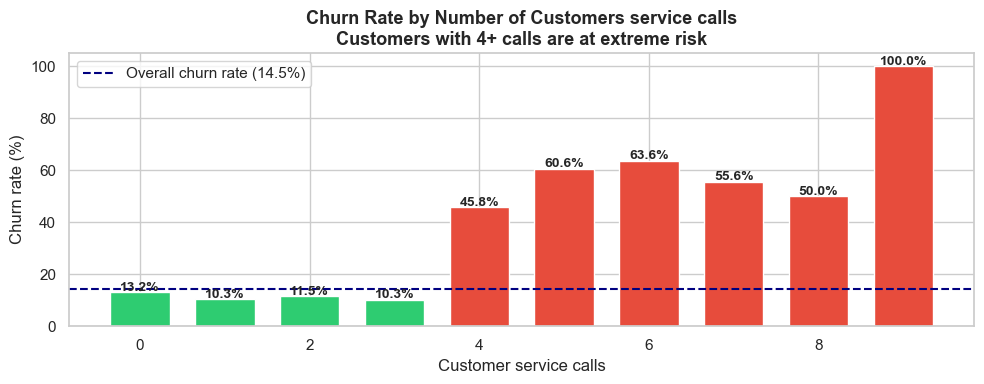

In [15]:
# Churn Rate by customer service calls

plt.figure(figsize=(10,4))
churn_rate=data.groupby('CustServCalls')['Churn'].mean()*100
colors=['#e74c3c' if v>30 else '#f39c12' if v>15 else '#2ecc71'
        for v in churn_rate.values]
bars=plt.bar(churn_rate.index,churn_rate.values,
             color=colors,edgecolor='white',width=0.7)

for bar , val in zip(bars,churn_rate.values):
        plt.text(bar.get_x() + bar.get_width()/2 , bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center',fontsize=10,fontweight='bold')


plt.axhline(y=14.5,color='navy',linestyle='--',linewidth=1.5,
            label='Overall churn rate (14.5%)')

plt.title('Churn Rate by Number of Customers service calls\n'
          'Customers with 4+ calls are at extreme risk',fontsize=13,fontweight='bold')

plt.xlabel('Customer service calls')
plt.ylabel('Churn rate (%)')
plt.legend()
plt.tight_layout()

plt.savefig('churn_by_calls.png',dpi=150,bbox_inches='tight')

In [16]:
# Check Contract Renewal & data plan impact on churn 
# Correlation heatmap 
# Finally select the important feature

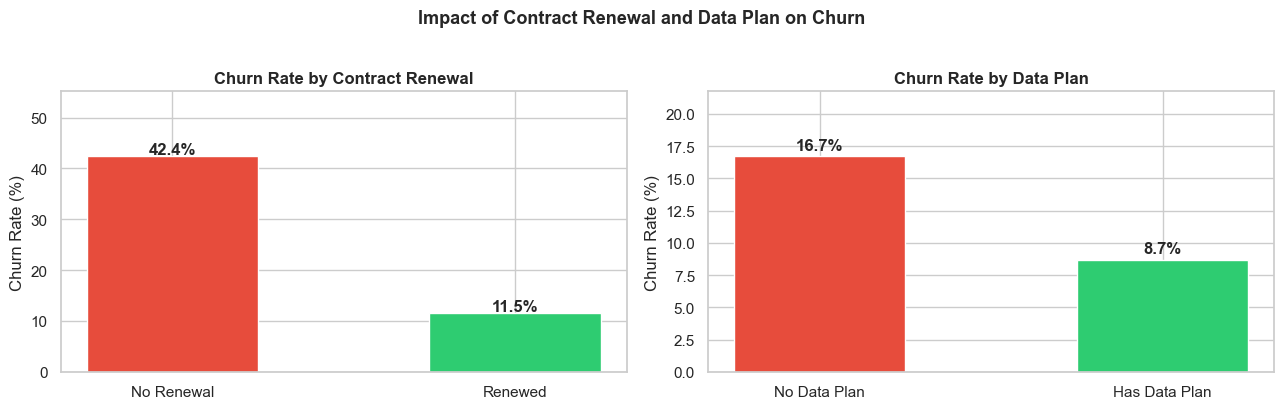

In [17]:
# Contract Renewal & Data Plan Impact
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, xlabels in zip(
    axes,
    ['ContractRenewal', 'DataPlan'],
    ['Churn Rate by Contract Renewal', 'Churn Rate by Data Plan'],
    [['No Renewal', 'Renewed'], ['No Data Plan', 'Has Data Plan']]
):
    rate = data.groupby(col)['Churn'].mean() * 100
    bars = ax.bar(xlabels, rate.values,
                  color=['#e74c3c', '#2ecc71'], edgecolor='white', width=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Churn Rate (%)')
    ax.set_ylim(0, max(rate.values) * 1.3)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{bar.get_height():.1f}%', ha='center', fontsize=12, fontweight='bold')
plt.suptitle('Impact of Contract Renewal and Data Plan on Churn',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('contract_dataplan.png', dpi=150, bbox_inches='tight')
plt.show()


In [18]:
# Mean Feature values by Churn Group 

print('Avergae feature values - churned vs retained:')  
print('(show the features difference most between the two group)\n')
comparison=data.groupby('Churn').mean().round(3).T
comparison.columns=['Retained (0)', 'Churned (1)']
comparison['Differences']=(comparison['Churned (1)'] - comparison['Retained (0)']).round(3)
print(comparison.to_string())

Avergae feature values - churned vs retained:
(show the features difference most between the two group)

                 Retained (0)  Churned (1)  Differences
AccountWeeks          100.794      102.665        1.871
ContractRenewal         0.935        0.716       -0.219
DataPlan                0.295        0.166       -0.129
DataUsage               0.862        0.547       -0.315
CustServCalls           1.450        2.230        0.780
DayMins               175.176      206.914       31.738
DayCalls              100.283      101.335        1.052
MonthlyCharge          55.816       59.190        3.374
OverageFee              9.955       10.623        0.668
RoamMins               10.159       10.700        0.541


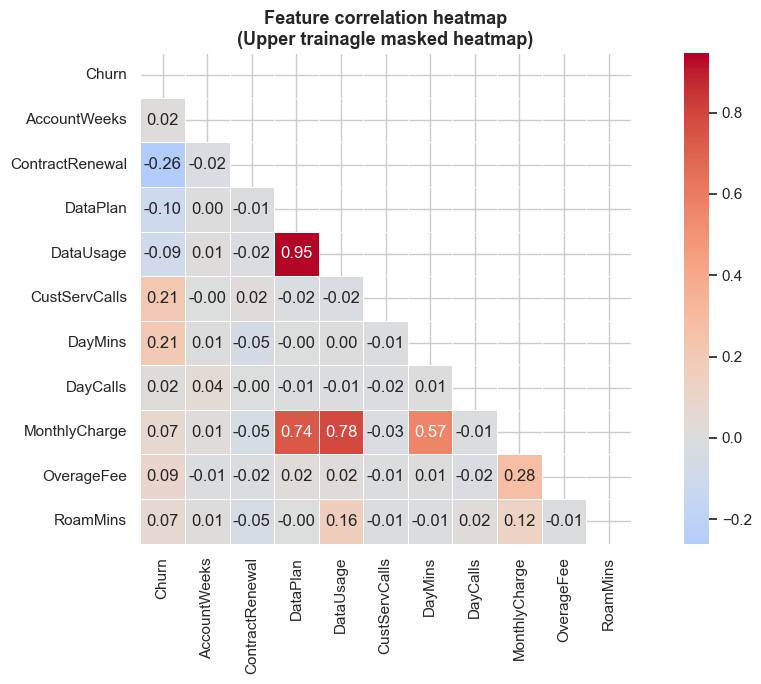

In [19]:
# Correlation Heatmap

plt.figure(figsize=(11,7))
mask=np.triu(np.ones_like(data.corr(),dtype=bool))
sns.heatmap(data.corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,linewidths=0.5,mask=mask,square=True)

plt.title("Feature correlation heatmap\n"
          '(Upper trainagle masked heatmap)',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.savefig('correlation heatmap.png', dpi=150,bbox_inches='tight')
plt.show()

Key finding : DayMins & MonthlyCharges are correlated at r=0.57 
MonthlyCharges will be dropped to avoid multicollinearity

# EDA Summary

* Only 14.5 % of customers are churned  ( Class imbalance must be handled in modelling)
* Customers with 4+ services calls churn at 50%+  (Stronger single churn prediction)
* Customers withoput contract renewal churn 3x more (key retention metrcis)
* Customer without a data plan churn siginificantly more (promote data plans)
* DayMins and MonthlyCharge are correlated at r=0.57 (Drop Monthly Charges)


# Feature Engineering
Raw features don't always capture the full picture . we create a new feature or logged feature to give the modl stronger signal

In [20]:
# Log transformation

data['DataUsage_log']=np.log1p(data['DataUsage'])
data['CustServCalls_log']=np.log1p(data['CustServCalls'])
data['OverageFee_log']=np.log1p(data['OverageFee'])

# 4+ calls = danger zone for churn 
data['HighServiceCalls']= (data['CustServCalls']>=4).astype(int)

# no data plan and zero usage of data = disengaged customer(also at risk)
data['NoDataEngagement']=(data['DataPlan']==0)&(data['DataUsage']==0).astype(int)

print('New feature created:')
print(data[['CustServCalls','CustServCalls_log','DataUsage','DataUsage_log','HighServiceCalls','NoDataEngagement']])

New feature created:
      CustServCalls  CustServCalls_log  DataUsage  DataUsage_log  \
0                 1           0.693147       2.70       1.308333   
1                 1           0.693147       3.70       1.547563   
2                 0           0.000000       0.00       0.000000   
3                 2           1.098612       0.00       0.000000   
4                 3           1.386294       0.00       0.000000   
...             ...                ...        ...            ...   
3328              2           1.098612       2.67       1.300192   
3329              3           1.386294       0.34       0.292670   
3330              2           1.098612       0.00       0.000000   
3331              2           1.098612       0.00       0.000000   
3332              0           0.000000       3.70       1.547563   

      HighServiceCalls  NoDataEngagement  
0                    0             False  
1                    0             False  
2                    0           

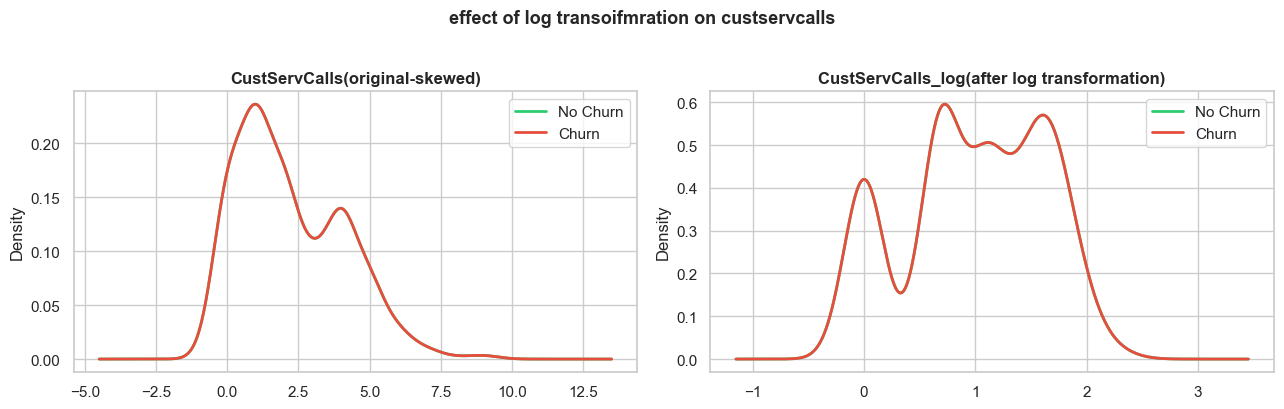

In [21]:
# Visualise effect fro log transformation on custvercalls

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,col,title in zip(
    axes,
    ['CustServCalls','CustServCalls_log'],
    ['CustServCalls(original-skewed)','CustServCalls_log(after log transformation)']   
):
    for chrun_val,color,label in [(0,'#2ecc71','No Churn'),(1,'#e74c3c','Churn')]:
        data[data['Churn']==churn_val][col].plot(
            kind='kde',ax=ax,color=color,label=label,linewidth=2)
        ax.set_title(title,fontsize=12,fontweight='bold')
        ax.legend()

plt.suptitle("effect of log transoifmration on custservcalls",fontsize=13,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

# Data Preprocessing

In [22]:
data.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins', 'DataUsage_log', 'CustServCalls_log', 'OverageFee_log',
       'HighServiceCalls', 'NoDataEngagement'],
      dtype='object')

In [23]:
features=['AccountWeeks',
          'ContractRenewal',
          'DataPlan',
          'DataUsage_log',
          'CustServCalls',
          'DayMins',
          'OverageFee_log',
          'RoamMins',
          'HighServiceCalls',
          'NoDataEngagement']



X=data[features]
y=data['Churn']


# stratify=y ensure same churn ration in train and test splits
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#Fit on only train only and then trasnform both
scaler=StandardScaler()
X_train_sc=scaler.fit_transform(X_train)
X_test_sc=scaler.transform(X_test)


print(f'Training set : {len(y_train):,} rows | Churn rate:{y_train.mean()*100:.1f}%')
print(f'Test set : {len(y_test):,} rows | Churn rate:{y_test.mean()*100:.1f}%')

Training set : 2,666 rows | Churn rate:14.5%
Test set : 667 rows | Churn rate:14.5%


# Model Building

Handling Class imbalance: All models use wither class_weight='balanced' / scale_pos_weight=6 (Xgbosst) - this tells each model that missing a churner is more costly than a false alarm and to weight the minority class accordingly

# Logsitic Regression

A simple linear modle , good baseline - fast , interpertable , and explaninable to non techincal stake holders

In [24]:
lr=LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42)
lr.fit(X_train_sc,y_train)
y_pred_lr=lr.predict(X_test_sc)
y_prob_lr=lr.predict_proba(X_test_sc)[:,1]

print('Logistic Regression')
print('='*50)

print(classification_report(y_test,y_pred_lr,target_names=['No Churn','Churn']))

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.97      0.84      0.90       570
       Churn       0.46      0.82      0.59        97

    accuracy                           0.84       667
   macro avg       0.71      0.83      0.74       667
weighted avg       0.89      0.84      0.85       667



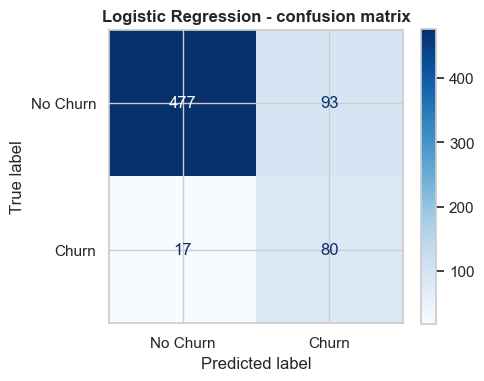

In [25]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_lr,
    display_labels=['No Churn','Churn'],cmap='Blues',ax=ax
)

ax.set_title('Logistic Regression - confusion matrix',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

# Decision Tree

In [26]:
dt=DecisionTreeClassifier(max_depth=5,class_weight='balanced',random_state=42)
dt.fit(X_train_sc,y_train)
y_pred_dt=dt.predict(X_test_sc)
y_prob_dt=dt.predict_proba(X_test_sc)[:,1]

print('Decision tree')
print('='*50)
print(classification_report(y_test,y_pred_dt,target_names=['No Churn','Churn']))

Decision tree
              precision    recall  f1-score   support

    No Churn       0.95      0.87      0.91       570
       Churn       0.49      0.74      0.59        97

    accuracy                           0.85       667
   macro avg       0.72      0.81      0.75       667
weighted avg       0.89      0.85      0.86       667



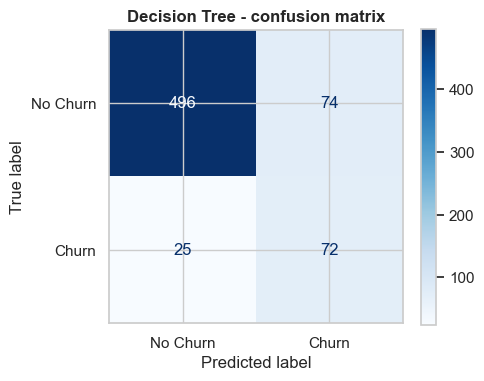

In [27]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_dt,
    display_labels=['No Churn','Churn'],cmap='Blues',ax=ax
)

ax.set_title('Decision Tree - confusion matrix',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

# Random Forest
An ensemble of many decision trees.Reducing overfitting by avergae predictions across trees. Usually outperform a dcision tree

In [28]:
rf=RandomForestClassifier(n_estimators=100,class_weight='balanced',random_state=42)
rf.fit(X_train_sc,y_train)
y_pred_rf=rf.predict(X_test_sc)
y_prob_rf=rf.predict_proba(X_test_sc)[:,1]

print("Random Forest")
print('='*50)
print(classification_report(y_test,y_pred_rf,target_names=["No Churn",'Churn']))

Random Forest
              precision    recall  f1-score   support

    No Churn       0.93      0.98      0.95       570
       Churn       0.83      0.57      0.67        97

    accuracy                           0.92       667
   macro avg       0.88      0.77      0.81       667
weighted avg       0.92      0.92      0.91       667



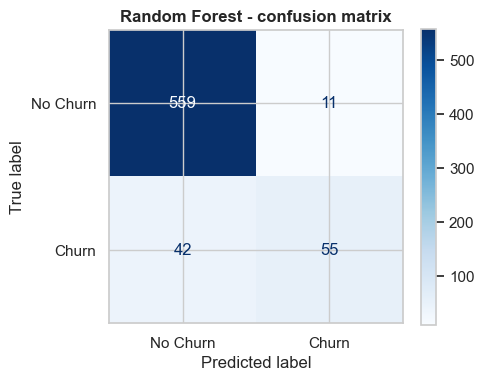

In [29]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_rf,
    display_labels=['No Churn','Churn'],cmap='Blues',ax=ax
)

ax.set_title('Random Forest - confusion matrix',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

# XGBoost

Builds trees sequentially ach one correcting the results of the previous trees,
scale_pos_weight

In [ ]:
xgb=XGBClassifier(
    scale_pos_weight=6,
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_sc,y_train)
y_pred_xgb=xgb.predict(X_test_sc)
y_prob_xgb=xgb.predict_proba(X_test_sc)[:,1]

print("XGBoost")
print('='*50)
print(classification_report(y_test,y_pred_xgb,target_names=['No churn','Churn']))

XGBoost
              precision    recall  f1-score   support

    No churn       0.95      0.92      0.94       570
       Churn       0.62      0.72      0.67        97

    accuracy                           0.90       667
   macro avg       0.79      0.82      0.80       667
weighted avg       0.90      0.90      0.90       667



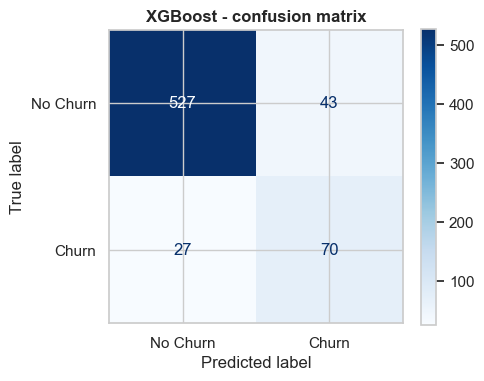

In [31]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_xgb,
    display_labels=['No Churn','Churn'],cmap='Blues',ax=ax
)

ax.set_title('XGBoost - confusion matrix',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

# Model Comparison

In [32]:
results=[]

for name,y_pred,y_prob in [
    ('LogisticRegression',y_pred_lr,y_prob_lr),
    ('Deision Tree',y_pred_dt,y_prob_dt),
    ('Random Forest',y_pred_rf,y_prob_rf),
    ('XGBClassifier',y_pred_xgb,y_prob_xgb)
]:
    results.append({
        'Model' : name,
        'Accuracy': round(accuracy_score(y_test,y_pred),4),
        'Precision':round(precision_score(y_test,y_pred),4),
        'Recall':round(recall_score(y_test,y_pred),4),
        'F1':round(f1_score(y_test,y_pred),4),
        'ROC_AUC':round(roc_auc_score(y_test,y_pred),4)
        })
    
comparison=pd.DataFrame(results)
print(comparison.sort_values('ROC_AUC',ascending=False).to_string(index=False))

             Model  Accuracy  Precision  Recall     F1  ROC_AUC
LogisticRegression    0.8351     0.4624  0.8247 0.5926   0.8308
     XGBClassifier    0.8951     0.6195  0.7216 0.6667   0.8231
      Deision Tree    0.8516     0.4932  0.7423 0.5926   0.8062
     Random Forest    0.9205     0.8333  0.5670 0.6748   0.7739


* 0.50 - model is randomly guessing
* 0.70 - model can reasonably distinhuish customers
* 0.80 - model distinguishes customers well
* 0.90 - model distinguishes customers very well
* 1.00 - perfect sepearation

# Cross validation

In [38]:
from sklearn.model_selection import StratifiedKFold,cross_val_score

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print('5 fold cross validation - f1 Score(Churn Score):')
print('='*50)
for name,model in [
    ('LogisticRegression',lr),
    ('Decesion Tree',dt),
    ('Random Forest',rf),
    ('XGBooost', xgb)
]:
    scores=cross_val_score(model,X_train_sc,y_train,cv=cv,scoring='f1')
    print(f'{name:<22}:{scores.mean():.4f}')



5 fold cross validation - f1 Score(Churn Score):
LogisticRegression    :0.6234
Decesion Tree         :0.6580
Random Forest         :0.7143
XGBooost              :0.7393


# Feature Importance

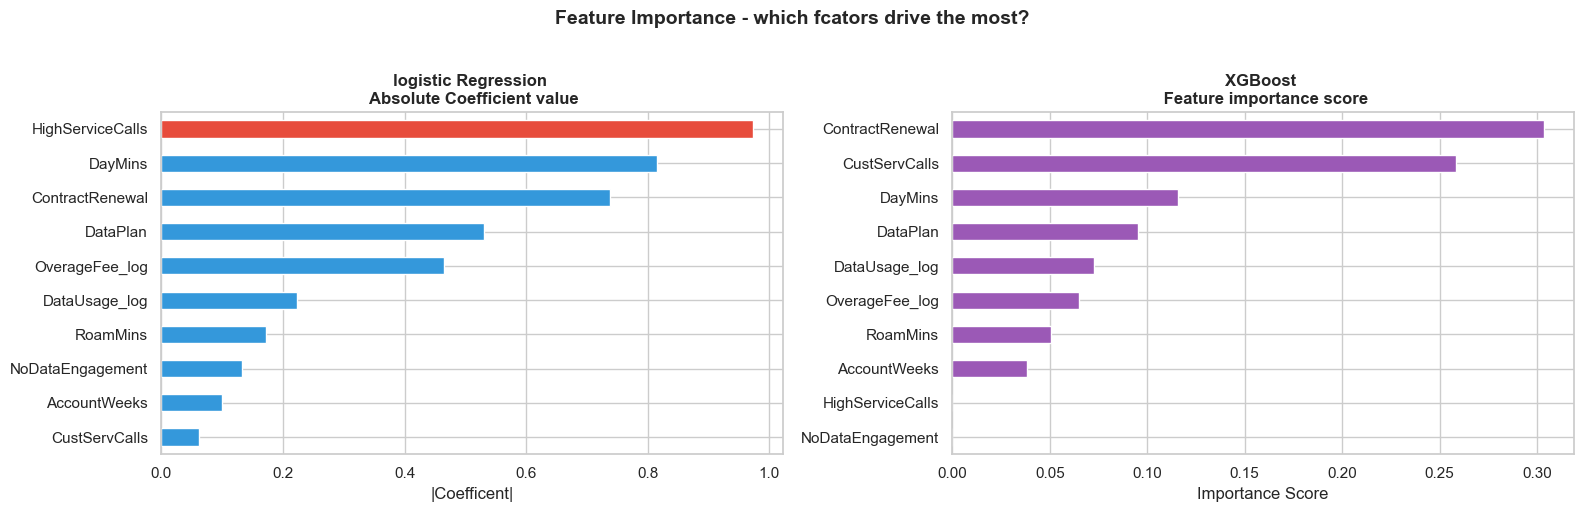

top 5 features (XGBoost)
ContractRenewal    0.3037
CustServCalls      0.2585
DayMins            0.1158
DataPlan           0.0953
DataUsage_log      0.0729
dtype: float32


In [47]:
fig,axes=plt.subplots(1,2, figsize=(16,5))

#logistic Regression

lr_imp=pd.Series(np.abs(lr.coef_[0]),index=features).sort_values(ascending=True)
colors_lr=['#e74c3c' if v==lr_imp.max() else '#3498db' for v in lr_imp.values]
lr_imp.plot(kind='barh',ax=axes[0], color=colors_lr,edgecolor='white')
axes[0].set_title('logistic Regression \n Absolute Coefficient value', fontsize=12,fontweight='bold')
axes[0].set_xlabel('|Coefficent|')

#XGboost - feature importance
xgb_imp=pd.Series(xgb.feature_importances_, index=features).sort_values(ascending=True)
colors_xgb=['#e74c3c' if v==lr_imp.max() else '#9b59b6' for v in xgb_imp.values]
xgb_imp.plot(kind='barh',ax=axes[1], color=colors_xgb,edgecolor='white')
axes[1].set_title('XGBoost \n Feature importance score', fontsize=12,fontweight='bold')
axes[1].set_xlabel('Importance Score')

plt.suptitle('Feature Importance - which fcators drive the most?',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

print('top 5 features (XGBoost)')
print(xgb_imp.sort_values(ascending=False).head().round(4))

# Business Insights & Recommendations

In [53]:
y_prob_final=xgb.predict_proba(X_test_sc)[:,1]

risk_table=pd.DataFrame({
    'Churn_probbality_%':(y_prob_final*100).round(1),
    'Predicted Churn':y_pred_xgb,
    'Actual_Churn':y_test.values
}).sort_values('Churn_probbality_%',ascending=False).reset_index(drop=True)

risk_table.index +=1
print(' top 15 customers to target')
print(risk_table.head(30).to_string())

 top 15 customers to target
    Churn_probbality_%  Predicted Churn  Actual_Churn
1           100.000000                1             1
2            99.900002                1             1
3            99.900002                1             1
4            99.900002                1             1
5            99.900002                1             1
6            99.800003                1             1
7            99.699997                1             1
8            99.699997                1             1
9            99.599998                1             1
10           99.599998                1             1
11           99.599998                1             1
12           99.500000                1             1
13           99.500000                1             1
14           99.500000                1             1
15           99.500000                1             1
16           99.500000                1             1
17           99.400002                1             0


In [60]:
# Business impact calacuate

flagged=(y_pred_xgb==1).sum()
caught=((y_pred_xgb==1)&(y_test.values==1)).sum()
missed=((y_pred_xgb==0)&(y_test.values==1)).sum()
total_ch=int(y_test.sum())

print('='*52)
print('                 Busines impact summary                                  ')
print('='*52)
print(f'Total customers evaluated:{len(y_test):,}')
print(f'Actual customers in test set:{total_ch}')
print(f'Churners caught by model :{caught},({caught/total_ch*100:.0f}%)')
print(f' Churners missed: {missed}')
print(f'Flase alarams (safe falgged):{flagged-caught}')
print('='*52)
print(f'Assumption:')
print(f'Retention offer cost: $50 per customer')
print(f'Average annual revenue :$500 per customer')
print(f'Campaign cost:${flagged * 50:,}')
print(f'Revenue protected:${caught * 500:,}')
print(f'Net Profit:${(caught * 500)-(flagged*50):,}')


                 Busines impact summary                                  
Total customers evaluated:667
Actual customers in test set:97
Churners caught by model :70,(72%)
 Churners missed: 27
Flase alarams (safe falgged):43
Assumption:
Retention offer cost: $50 per customer
Average annual revenue :$500 per customer
Campaign cost:$5,650
Revenue protected:$35,000
Net Profit:$29,350


In [ ]:
# Key insights with evidance
# Model results summary  (why xgboost was selected)
# what i learned
